# 🏆 Best Model Configuration from notebook_ap.ipynb

Based on the experiments in `notebook_ap.ipynb`, this notebook creates a model with the best performing configuration.

**Configuration Source:** Experiment comparison results from notebook_ap.ipynb

In [51]:
# ========== IMPORTS ==========
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import sys
import os
import glob
from pathlib import Path
from sklearn.preprocessing import StandardScaler

# Add parent directory to path to access utils
sys.path.append(str(Path.cwd().parent))

# Import custom modules
from utils.simple_lds_loss import SimpleLDSLoss
from utils.reproducibility_utils import seed_everything
from utils.band_mapping import load_band_mapping
from utils.kaggle_metric import score
from utils.data_loading import load_data, load_test_data

# Load band mapping dictionary
shot_band_mapping = load_band_mapping()

print("✅ All imports successful")
print(f"✅ Loaded {len(shot_band_mapping)} sideslip band mappings")

✅ All imports successful
✅ Loaded 234 sideslip band mappings


In [52]:
# ========== SET SEED FOR REPRODUCIBILITY ==========
seed_everything(42)
print("✅ Seed set to 42")

✅ Seed set to 42


In [53]:
class RNN(nn.Module):
    """
    Recurrent Neural Network for sideSlip prediction with flexible initialization.
    """

    def __init__(self, 
                 input_size,          # Anzahl der Features
                 hidden_size=64,      # Größe der RNN-Units
                 num_layers=1,        # Anzahl der RNN-Layers
                 fc_units=64,         # Anzahl Units der Fully Connected Layer
                 output_size=1,       # Dimension des Outputs
                 activation_fct=nn.ReLU(), 
                 dropout=[0.2, 0, 0], # Dropouts: [input, nach RNN, nach FC]
                 rnn_type='RNN',      # 'RNN', 'LSTM' oder 'GRU'
                 rnn_nonlinearity='tanh'  # nur für RNN
                 ):
        super(RNN, self).__init__()

        self.dropout1 = nn.Dropout(dropout[0])
        self.dropout2 = nn.Dropout(dropout[1])
        self.dropout3 = nn.Dropout(dropout[2])
        self.activation_fct = activation_fct

        # RNN Layer
        if rnn_type.upper() == 'RNN':
            self.rnn_layer = nn.RNN(input_size=input_size,
                                    hidden_size=hidden_size,
                                    num_layers=num_layers,
                                    nonlinearity=rnn_nonlinearity,
                                    batch_first=True)
        elif rnn_type.upper() == 'LSTM':
            self.rnn_layer = nn.LSTM(input_size=input_size,
                                     hidden_size=hidden_size,
                                     num_layers=num_layers,
                                     batch_first=True)
        elif rnn_type.upper() == 'GRU':
            self.rnn_layer = nn.GRU(input_size=input_size,
                                    hidden_size=hidden_size,
                                    num_layers=num_layers,
                                    batch_first=True)
        else:
            raise ValueError(f"Unsupported rnn_type {rnn_type}")

        # Fully Connected Layer
        self.fc = nn.Linear(hidden_size, fc_units)
        self.output_layer = nn.Linear(fc_units, output_size)

    def forward(self, x):
        x = self.dropout1(x)
        x, _ = self.rnn_layer(x)  # output shape: (batch, seq_len, hidden_size)
        x = x[:, -1, :]            # nur letzter Zeitschritt
        x = self.dropout2(x)
        x = self.activation_fct(self.fc(x))
        x = self.dropout3(x)
        x = self.output_layer(x)
        return x


In [54]:
# ========== LOAD ALL TRAINING DATA FOR CROSS-VALIDATION ==========
print("\n" + "="*80)
print("📂 LOADING DATA FOR CROSS-VALIDATION")
print("="*80)

# Pfad zu deinem Ordner
path = "../datasets_challenge/train"

# Alle CSV-Dateien im Ordner laden und sortieren
csv_files = sorted(glob.glob(os.path.join(path, "*.csv")))
print(f"Gefundene CSV-Dateien: {len(csv_files)}")

# ALLE Dateien für Cross-Validation laden (keine feste Val-Datei mehr)
all_train_df = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)

print(f"Gesamt-Trainings-Samples: {len(all_train_df):,}")

# ========== VELOCITY THRESHOLDING ==========
threshold_column = "vxCG"
threshold_value = 3.0

print(f"\nBefore threshold: {len(all_train_df):,} samples")
all_train_df = all_train_df[all_train_df[threshold_column] > threshold_value].reset_index(drop=True)
print(f"After threshold:  {len(all_train_df):,} samples")

# ========== ANALYZE SHOT DISTRIBUTION ==========
all_train_df['sideslip_rounded'] = all_train_df['sideSlip'].round(1)
all_train_df['shot_band'] = all_train_df['sideslip_rounded'].map(shot_band_mapping)

band_counts = all_train_df['shot_band'].value_counts()
print("\n" + "="*80)
print("📊 SHOT DISTRIBUTION IN ALL TRAINING DATA")
print("="*80)
for band in ['many', 'medium', 'few']:
    count = band_counts.get(band, 0)
    pct = 100 * count / len(all_train_df)
    print(f"{band.capitalize()}-Shot: {count:,} samples ({pct:.1f}%)")

# ========== CREATE CROSS-VALIDATION SPLITS ==========
from sklearn.model_selection import KFold

n_folds = 5
kfold = KFold(n_splits=n_folds, shuffle=True, random_state=42)
fold_splits = list(kfold.split(all_train_df))

print(f"\n✅ Created {n_folds}-fold cross-validation splits")

# ========== PREPARE DATA PROCESSING PARAMETERS ==========
drop_columns = ["sideSlip", "vyCG", "time", "longitude", "latitude", "sideslip_rounded", "shot_band"]
target_column = "sideSlip"
sequence_length = 20
batch_size = 512

# Create sequences function
def create_sequences(X, y, seq_len):
    sequences = []
    targets = []
    for i in range(len(X) - seq_len):
        seq_x = X[i:i+seq_len]
        seq_y = y[i+seq_len]
        sequences.append(seq_x)
        targets.append(seq_y)
    return np.array(sequences), np.array(targets)

print(f"\n✅ Cross-Validation setup complete")
print(f"   Total samples: {len(all_train_df):,}")
print(f"   Number of folds: {n_folds}")
print(f"   Sequence length: {sequence_length}")
print(f"   Batch size: {batch_size}")


📂 LOADING DATA FOR CROSS-VALIDATION
Gefundene CSV-Dateien: 22
Gesamt-Trainings-Samples: 275,226

Before threshold: 275,226 samples
After threshold:  137,935 samples

📊 SHOT DISTRIBUTION IN ALL TRAINING DATA
Many-Shot: 125,703 samples (91.1%)
Medium-Shot: 9,489 samples (6.9%)
Few-Shot: 2,743 samples (2.0%)

✅ Created 5-fold cross-validation splits

✅ Cross-Validation setup complete
   Total samples: 137,935
   Number of folds: 5
   Sequence length: 20
   Batch size: 512
Gesamt-Trainings-Samples: 275,226

Before threshold: 275,226 samples
After threshold:  137,935 samples

📊 SHOT DISTRIBUTION IN ALL TRAINING DATA
Many-Shot: 125,703 samples (91.1%)
Medium-Shot: 9,489 samples (6.9%)
Few-Shot: 2,743 samples (2.0%)

✅ Created 5-fold cross-validation splits

✅ Cross-Validation setup complete
   Total samples: 137,935
   Number of folds: 5
   Sequence length: 20
   Batch size: 512


In [55]:
# ========== BEST MODEL CONFIGURATION ==========
print("\n" + "="*80)
print("🏆 BEST MODEL CONFIGURATION")
print("="*80)

device = "cuda" if torch.cuda.is_available() else "cpu"

# Architecture parameters
hidden_size_best = 32
fc_units_best = 32
num_layers_best = 2
dropout_probs_best = [0.2, 0.3, 0.2]

# Training parameters
lr = 0.0005
weight_decay = 1e-4

# Scheduler parameters
scheduler_mode = 'min'
scheduler_factor = 0.5
scheduler_patience = 3
scheduler_min_lr = 1e-6

# Training configuration
num_epochs = 50
early_stop_thresh = 10

# Loss strategy - REDUCED LDS (trying to get Many-Shot < 0.2°)
use_lds_best = True
lds_ks = 5
lds_sigma = 2.0

print(f"\n🏗️  Architecture:")
print(f"   - RNN Type: LSTM")
print(f"   - Hidden Size: {hidden_size_best}")
print(f"   - FC Units: {fc_units_best}")
print(f"   - Num Layers: {num_layers_best}")
print(f"   - Dropout: {dropout_probs_best}")
print(f"\n⚙️  Training:")
print(f"   - Learning Rate: {lr}")
print(f"   - Weight Decay: {weight_decay}")
print(f"   - Early Stopping: {early_stop_thresh} epochs")
print(f"\n🎯 Strategy:")
print(f"   - Loss: LDS (ks={lds_ks}, sigma={lds_sigma}) [REDUCED - targeting Many < 0.2°]")


🏆 BEST MODEL CONFIGURATION

🏗️  Architecture:
   - RNN Type: LSTM
   - Hidden Size: 32
   - FC Units: 32
   - Num Layers: 2
   - Dropout: [0.2, 0.3, 0.2]

⚙️  Training:
   - Learning Rate: 0.0005
   - Weight Decay: 0.0001
   - Early Stopping: 10 epochs

🎯 Strategy:
   - Loss: LDS (ks=5, sigma=2.0) [REDUCED - targeting Many < 0.2°]


In [56]:
# ========== CROSS-VALIDATION TRAINING LOOP ==========
print("\n" + "="*80)
print("🚀 STARTING CROSS-VALIDATION TRAINING")
print("="*80)

# Storage for fold results
fold_models = []
fold_scalers = []
fold_scores = []

for fold_idx, (train_indices, val_indices) in enumerate(fold_splits):
    print(f"\n{'='*80}")
    print(f"📁 FOLD {fold_idx + 1}/{n_folds}")
    print(f"{'='*80}")
    
    # Split data for this fold
    train_df_fold = all_train_df.iloc[train_indices].copy()
    val_df_fold = all_train_df.iloc[val_indices].copy()
    
    # Check shot distribution in this fold
    val_band_counts = val_df_fold['shot_band'].value_counts()
    print(f"\nValidation Set Distribution (Fold {fold_idx + 1}):")
    for band in ['many', 'medium', 'few']:
        count = val_band_counts.get(band, 0)
        pct = 100 * count / len(val_df_fold)
        print(f"  {band.capitalize()}-Shot: {count:,} ({pct:.1f}%)")
    
    # Prepare features and targets
    feature_columns = [col for col in train_df_fold.columns if col not in drop_columns]
    
    X_train = train_df_fold[feature_columns].values
    y_train = train_df_fold[target_column].values.reshape(-1, 1)
    
    X_val = val_df_fold[feature_columns].values
    y_val = val_df_fold[target_column].values.reshape(-1, 1)
    
    # Standardization
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    
    # Create sequences
    X_train_seq, y_train_seq = create_sequences(X_train_scaled, y_train, sequence_length)
    X_val_seq, y_val_seq = create_sequences(X_val_scaled, y_val, sequence_length)
    
    # Create DataLoaders
    train_dataset = TensorDataset(torch.tensor(X_train_seq, dtype=torch.float32),
                                  torch.tensor(y_train_seq, dtype=torch.float32))
    val_dataset = TensorDataset(torch.tensor(X_val_seq, dtype=torch.float32),
                                torch.tensor(y_val_seq, dtype=torch.float32))
    
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    
    print(f"\nData prepared:")
    print(f"  Train sequences: {len(X_train_seq):,}")
    print(f"  Val sequences: {len(X_val_seq):,}")
    
    # Create model for this fold
    seed_everything(42 + fold_idx)  # Different seed per fold
    
    model = RNN(
        input_size=X_train_seq.shape[2],
        hidden_size=hidden_size_best,
        num_layers=num_layers_best,
        fc_units=fc_units_best,
        dropout=dropout_probs_best,
        rnn_type='LSTM',
        output_size=1
    ).to(device)
    
    # Create LDS Loss with baseline parameters
    criterion = SimpleLDSLoss(
        train_targets=y_train_seq.flatten(),
        lds_ks=lds_ks,
        lds_sigma=lds_sigma
    )
    
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=scheduler_factor, 
        patience=scheduler_patience, min_lr=scheduler_min_lr
    )
    
    print(f"\n🏋️  Training Fold {fold_idx + 1}...")
    
    # Training loop for this fold
    best_val_loss = np.inf
    best_epoch = -1
    patience_counter = 0
    
    for epoch in range(num_epochs):
        # Training phase
        model.train()
        running_loss = 0.0
        
        for x, y in train_loader:
            X_batch, y_batch = x.to(device), y.to(device).reshape([len(y), 1])
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, y_batch)
            running_loss += loss.item()
            loss.backward()
            optimizer.step()
        
        avg_train_loss = running_loss / len(train_loader)
        
        # Validation phase
        model.eval()
        running_val_loss = 0.0
        
        with torch.no_grad():
            for x, y in val_loader:
                X_batch, y_batch = x.to(device), y.to(device).reshape([len(y), 1])
                pred = model(X_batch)
                val_loss = criterion(pred, y_batch)
                running_val_loss += val_loss.item()
        
        avg_val_loss = running_val_loss / len(val_loader)
        scheduler.step(avg_val_loss)
        
        # Check for improvement
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_epoch = epoch
            best_model_state = model.state_dict().copy()
            patience_counter = 0
        else:
            patience_counter += 1
        
        if (epoch + 1) % 5 == 0:
            print(f"  Epoch {epoch+1:2d}/{num_epochs} | Train: {avg_train_loss:.5f} | Val: {avg_val_loss:.5f}")
        
        if patience_counter >= early_stop_thresh:
            print(f"  Early stopping at epoch {epoch+1} (best: {best_epoch+1})")
            break
    
    # Load best model for this fold
    model.load_state_dict(best_model_state)
    
    # Evaluate on validation set
    model.eval()
    val_preds = []
    val_gts = []
    
    with torch.no_grad():
        for x, y in val_loader:
            X_batch, y_batch = x.to(device), y.to(device).reshape([len(y), 1])
            pred = model(X_batch)
            val_preds.append(pred.cpu().numpy().flatten())
            val_gts.append(y_batch.cpu().numpy().flatten())
    
    val_gts = np.concatenate(val_gts)
    val_preds = np.concatenate(val_preds)
    
    # Calculate scores
    val_gts_rounded = np.round(val_gts, 1)
    bands = [shot_band_mapping.get(gt, 'unknown') for gt in val_gts_rounded]
    
    val_gt_df = pd.DataFrame({
        'id': range(len(val_gts)),
        'ground_truth_sideslip': val_gts,
        'band': bands
    })
    
    val_preds_df = pd.DataFrame({
        'id': range(len(val_preds)),
        'predicted_sideslip': val_preds
    })
    
    fold_result = score(val_gt_df, val_preds_df, 'id')
    fold_scores.append(fold_result)
    
    print(f"\n📈 Fold {fold_idx + 1} Validation Scores:")
    print(f"   Many-Shot:   {fold_result['many']:.3f}°")
    print(f"   Medium-Shot: {fold_result['medium']:.3f}°")
    print(f"   Few-Shot:    {fold_result['few']:.3f}°")
    
    # Store model and scaler
    fold_models.append(model)
    fold_scalers.append(scaler)

# ========== AGGREGATE CROSS-VALIDATION RESULTS ==========
print(f"\n{'='*80}")
print("📊 CROSS-VALIDATION SUMMARY")
print(f"{'='*80}")

many_scores = [f['many'] for f in fold_scores]
medium_scores = [f['medium'] for f in fold_scores]
few_scores = [f['few'] for f in fold_scores]

print(f"\nAverage Scores across {n_folds} folds:")
print(f"   Many-Shot:   {np.mean(many_scores):.3f}° ± {np.std(many_scores):.3f}°")
print(f"   Medium-Shot: {np.mean(medium_scores):.3f}° ± {np.std(medium_scores):.3f}°")
print(f"   Few-Shot:    {np.mean(few_scores):.3f}° ± {np.std(few_scores):.3f}°")

if np.mean(many_scores) > 0.2:
    print(f"\n⚠️  WARNING: Average Many-Shot MAE exceeds Kaggle constraint!")
else:
    print(f"\n✅ Average Many-Shot MAE satisfies Kaggle constraint (< 0.2°)")

print(f"\n✅ Cross-Validation Training Complete!")
print(f"   Trained {len(fold_models)} models")


🚀 STARTING CROSS-VALIDATION TRAINING

📁 FOLD 1/5

Validation Set Distribution (Fold 1):
  Many-Shot: 25,145 (91.1%)
  Medium-Shot: 1,867 (6.8%)
  Few-Shot: 575 (2.1%)

Data prepared:
  Train sequences: 110,328
  Val sequences: 27,567
✅ LDS enabled: gaussian kernel (ks=5, sigma=2.0)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.027, 6.829]
Weight mean: 1.000 (normalized to 1.0)


🏋️  Training Fold 1...

Data prepared:
  Train sequences: 110,328
  Val sequences: 27,567
✅ LDS enabled: gaussian kernel (ks=5, sigma=2.0)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.027, 6.829]
Weight mean: 1.000 (normalized to 1.0)


🏋️  Training Fold 1...
  Epoch  5/50 | Train: 0.03025 | Val: 0.04282
  Epoch  5/50 | Train: 0.03025 | Val: 0.04282
  Epoch 10/50 | Train: 0.02696 | Val: 0.04139
  Epoch 10/50 | Train: 0.02696 | Val: 0.04139
  Epoch 15/50 | Train: 0.02602 | Val: 0.04174
  Epoc

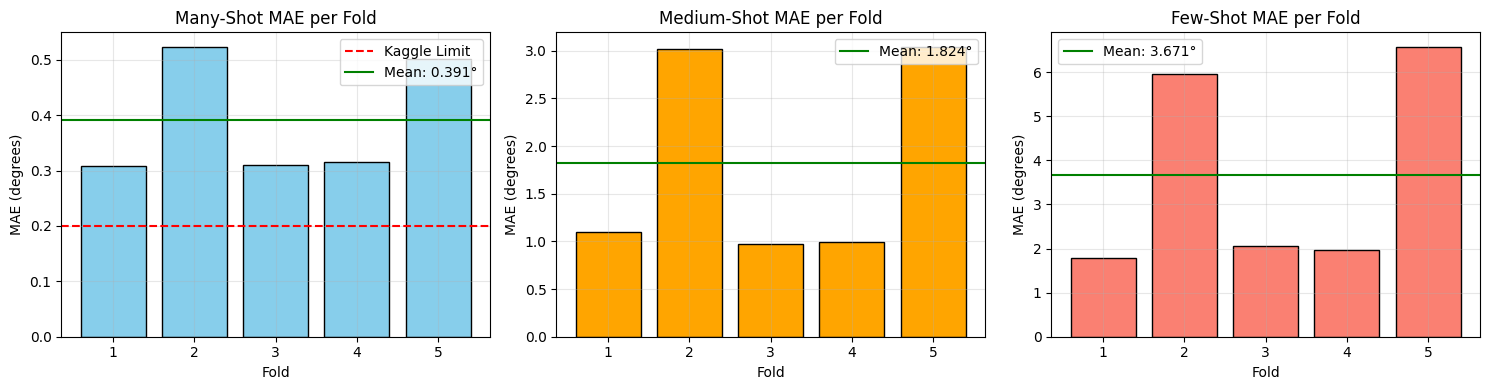


📊 Cross-Validation Statistics:
   Many-Shot:   0.391° (±0.099°)
   Medium-Shot: 1.824° (±0.987°)
   Few-Shot:    3.671° (±2.131°)


In [57]:
# ========== VISUALIZE CROSS-VALIDATION RESULTS ==========
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Plot 1: Many-Shot scores
many_scores = [f['many'] for f in fold_scores]
axes[0].bar(range(1, n_folds + 1), many_scores, color='skyblue', edgecolor='black')
axes[0].axhline(y=0.2, color='red', linestyle='--', label='Kaggle Limit')
axes[0].axhline(y=np.mean(many_scores), color='green', linestyle='-', label=f'Mean: {np.mean(many_scores):.3f}°')
axes[0].set_xlabel('Fold')
axes[0].set_ylabel('MAE (degrees)')
axes[0].set_title('Many-Shot MAE per Fold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Medium-Shot scores
medium_scores = [f['medium'] for f in fold_scores]
axes[1].bar(range(1, n_folds + 1), medium_scores, color='orange', edgecolor='black')
axes[1].axhline(y=np.mean(medium_scores), color='green', linestyle='-', label=f'Mean: {np.mean(medium_scores):.3f}°')
axes[1].set_xlabel('Fold')
axes[1].set_ylabel('MAE (degrees)')
axes[1].set_title('Medium-Shot MAE per Fold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot 3: Few-Shot scores
few_scores = [f['few'] for f in fold_scores]
axes[2].bar(range(1, n_folds + 1), few_scores, color='salmon', edgecolor='black')
axes[2].axhline(y=np.mean(few_scores), color='green', linestyle='-', label=f'Mean: {np.mean(few_scores):.3f}°')
axes[2].set_xlabel('Fold')
axes[2].set_ylabel('MAE (degrees)')
axes[2].set_title('Few-Shot MAE per Fold')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n📊 Cross-Validation Statistics:")
print(f"   Many-Shot:   {np.mean(many_scores):.3f}° (±{np.std(many_scores):.3f}°)")
print(f"   Medium-Shot: {np.mean(medium_scores):.3f}° (±{np.std(medium_scores):.3f}°)")
print(f"   Few-Shot:    {np.mean(few_scores):.3f}° (±{np.std(few_scores):.3f}°)")

In [58]:
# ========== ENSEMBLE PREDICTIONS ON TEST DATA ==========
print("\n" + "="*80)
print("🔮 GENERATING ENSEMBLE TEST PREDICTIONS")
print("="*80)

test_path = "../datasets_challenge/test"

# Load test data using pipeline
print("Loading test data using pipeline...")

# Use first fold's scaler as reference for pipeline creation
train_dataloader_tmp, val_dataloader_tmp, pipeline = load_data(
    train_path="../datasets_challenge/train",
    train_ratio=0.95,
    batchsize=batch_size,
    columns_to_drop=drop_columns[:5],  # Only base columns
    sequence_length=sequence_length,
    threshold=True,
    threshold_value=threshold_value,
    threshold_column=threshold_column,
    target=target_column,
    scaling=True,
    seed=42
)

print(f"✓ Pipeline created")

# Use pipeline to load test data
test_loader = load_test_data(
    test_path=test_path,
    batchsize=batch_size,
    pipeline=pipeline,
    load_anonymized_data=True
)

# Count samples
test_sample_count = 0
for batch_x, batch_y in test_loader:
    test_sample_count += len(batch_x)

print(f"\n📊 Test Data Statistics:")
print(f"   Total test samples: {test_sample_count:,}")
print(f"   Expected (Kaggle): 49,328")

if test_sample_count == 49328:
    print(f"   ✅ MATCH!")
else:
    print(f"   ⚠️  Mismatch!")

# ========== GENERATE PREDICTIONS FROM ALL FOLDS (ENSEMBLE) ==========
print(f"\n🎯 Generating predictions from {len(fold_models)} fold models...")

all_fold_predictions = []

for fold_idx, model in enumerate(fold_models):
    print(f"  Processing Fold {fold_idx + 1}/{len(fold_models)}...")
    
    model.eval()
    fold_preds = []
    
    with torch.no_grad():
        for x, _ in test_loader:
            X_batch = x.to(device)
            pred = model(X_batch)
            fold_preds.append(pred.reshape(-1).cpu().numpy())
    
    fold_preds = np.concatenate(fold_preds)
    all_fold_predictions.append(fold_preds)

# Average predictions across all folds (Ensemble)
ensemble_preds = np.mean(all_fold_predictions, axis=0)

print(f"\n✓ Ensemble predictions generated")
print(f"✓ Shape: {ensemble_preds.shape}")
print(f"✓ Prediction range: [{ensemble_preds.min():.2f}°, {ensemble_preds.max():.2f}°]")
print(f"✓ Prediction mean: {ensemble_preds.mean():.2f}°, std: {ensemble_preds.std():.2f}°")

# Analyze ensemble uncertainty
pred_std = np.std(all_fold_predictions, axis=0)
print(f"\n📊 Ensemble Uncertainty:")
print(f"   Mean prediction std: {pred_std.mean():.3f}°")
print(f"   Max prediction std:  {pred_std.max():.3f}°")

# ========== SAVE ENSEMBLE PREDICTIONS ==========
test_sequence_ids = np.arange(len(ensemble_preds))

y_pred_final = pd.DataFrame({
    "id": test_sequence_ids,
    "predicted_sideslip": ensemble_preds
})

print(f"\n📊 Submission Statistics:")
print(f"  - Predictions generated: {len(ensemble_preds):,}")
print(f"  - ID range: [{y_pred_final['id'].min()}, {y_pred_final['id'].max()}]")
print(f"  - Expected count: 49,328")

if len(y_pred_final) == 49328:
    print(f"\n✅ PERFECT! Exactly 49,328 samples")
else:
    print(f"\n⚠️  Got {len(y_pred_final):,} samples (expected 49,328)")

# Save to CSV
output_file = "predictions_apv3_ensemble.csv"
y_pred_final.to_csv(output_file, index=False)

print(f"\n✓ Ensemble predictions saved to '{output_file}'")
print(f"✓ Using {len(fold_models)}-fold ensemble averaging")
print(f"✓ Ready for Kaggle submission!")
print(f"\n📋 File preview:")
print(y_pred_final.head(10))


🔮 GENERATING ENSEMBLE TEST PREDICTIONS
Loading test data using pipeline...
../datasets_challenge/train\train_part_001.csv
../datasets_challenge/train\train_part_002.csv
../datasets_challenge/train\train_part_003.csv
../datasets_challenge/train\train_part_004.csv
../datasets_challenge/train\train_part_005.csv
../datasets_challenge/train\train_part_006.csv
../datasets_challenge/train\train_part_007.csv
../datasets_challenge/train\train_part_008.csv
../datasets_challenge/train\train_part_009.csv
../datasets_challenge/train\train_part_010.csv
../datasets_challenge/train\train_part_011.csv
../datasets_challenge/train\train_part_012.csv
../datasets_challenge/train\train_part_013.csv
../datasets_challenge/train\train_part_014.csv
../datasets_challenge/train\train_part_015.csv
../datasets_challenge/train\train_part_016.csv
../datasets_challenge/train\train_part_017.csv
../datasets_challenge/train\train_part_018.csv
../datasets_challenge/train\train_part_019.csv
../datasets_challenge/train\tra

c:\Repos\mait_g2_drift_challenge\.venv\Lib\site-packages\sklearn\pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(



📊 Test Data Statistics:
   Total test samples: 49,328
   Expected (Kaggle): 49,328
   ✅ MATCH!

🎯 Generating predictions from 5 fold models...
  Processing Fold 1/5...
  Processing Fold 2/5...
  Processing Fold 2/5...
  Processing Fold 3/5...
  Processing Fold 3/5...
  Processing Fold 4/5...
  Processing Fold 4/5...
  Processing Fold 5/5...
  Processing Fold 5/5...

✓ Ensemble predictions generated
✓ Shape: (49328,)
✓ Prediction range: [-4.36°, 4.04°]
✓ Prediction mean: -0.01°, std: 0.72°

📊 Ensemble Uncertainty:
   Mean prediction std: 0.419°
   Max prediction std:  3.620°

📊 Submission Statistics:
  - Predictions generated: 49,328
  - ID range: [0, 49327]
  - Expected count: 49,328

✅ PERFECT! Exactly 49,328 samples

✓ Ensemble predictions saved to 'predictions_apv3_ensemble.csv'
✓ Using 5-fold ensemble averaging
✓ Ready for Kaggle submission!

📋 File preview:
   id  predicted_sideslip
0   0            0.056417
1   1            0.088216
2   2            0.089012
3   3            0.0